In [3]:
import numpy as np
import pandas as pd
import math
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import glob
from scipy.spatial import ConvexHull, Delaunay, cKDTree


FUNCTIONS

In [4]:
def import_2pcf(path):
    '''Import .dat files for theory_2pcf'''
    files_names = sorted(glob.glob(f"{path}/id*2pcf.dat"))
    files_full = [np.loadtxt(file) for file in files_names]
    files = []

    for i in range(len(files_full)):
        data = files_full[i]
        row = [row[1] for row in data]
        files.append(row)

    return files

def convex_plot(principal_components,color='red'):
    '''Plot convex full for one PCA'''
    hull = ConvexHull(principal_components)
    for simplex in hull.simplices:
        plt.plot(principal_components[simplex,0],principal_components[simplex,1],color=color,linewidth=0.8)


def pca_fn(data, scaler, pca):
    '''Apply PCA on a set of points, return principal_components,expained_variance_ratio'''
    # Standardisation
    scaled_full = scaler.fit_transform(data)
    
    # PCA
    principal_components = pca.fit_transform(scaled_full)

    return principal_components, pca.explained_variance_ratio_


def project_new_data(new_data, scaler, pca):
    '''Project new dataset on chosen PCA'''
    # Standardisation
    scaled_new_data = scaler.transform(new_data)
    
    # Projection of new data on pre-existing principal components
    new_principal_components = pca.transform(scaled_new_data)
    
    return new_principal_components


def camb_crash_plot(lhs_camb_path, pca, color='red', s=25, label='CAMB crashes', marker='x'):
    '''Plot CAMB crashes'''
    params = pd.read_csv(lhs_camb_path)
    cambres = params['camb_res']
    params_crash = params[params['camb_res']==0]
    indices = params_crash.index

    plt.scatter(pca[indices,0],pca[indices,1],s=s, color=color, label=label, marker=marker)


def pca_without_camb_crash(lhs_camb_path,pca):
    '''Returns PCA projection without CAMB CRASHES'''
    params = pd.read_csv(lhs_camb_path)
    cambres = params['camb_res']
    params_crash = params[params['camb_res']==0]

    indices_to_exclude = params_crash.iloc[:, 0].values
    mask = np.ones(pca.shape[0], dtype=bool)
    mask[indices_to_exclude] = False

    pca_without_camb = pca[mask]
    return pca_without_camb



def maximin_distance_1D(pca, n_points, original_pca, selected_points=[]):
    """Take n_points among points, maximizing distance.
    pca = dataset to get points in (ex : pca without camb)
    original_pca = original points (to keep indices)"""
    pc1 = original_pca[:,0]
    pc2 = original_pca[:,1]
    selected_indices = []

    points = list(zip(pca[:,0],pca[:,1]))
    new_points = [] # New points exclusively from big LHS

    if isinstance(selected_points, np.ndarray):
        selected_points = list(zip(selected_points[:,0],selected_points[:,1]))

    if len(selected_points)==0:
        selected_points.append(points[0])  # Take first point (arbitrary)
        new_points.append(points[0])

    while len(selected_points) < n_points:
        max_min_distance = -1
        next_point = None
        
        for point in points:
            if point not in selected_points:
                min_distance = math.inf
                
                for selected_point in selected_points:
                    distance = abs(point[0] - selected_point[0])
                    if distance < min_distance:
                        min_distance = distance
                
                if min_distance > max_min_distance:
                    max_min_distance = min_distance
                    next_point = point
                    indice = np.where((np.array(pc1) == point[0]))[0][0]
        
        selected_points.append(next_point) # Contains 25 original + new points from big LHS
        new_points.append(next_point) # Contains new points from big LHS (for indices)
        selected_indices.append(indice)

    np.array(selected_points)
    np.array(new_points)
        
    return selected_indices

def maximin_distance_2D(pca, n_points, original_pca, selected_points=[]):
    """Take n_points among points, maximizing distance.
    pca = dataset to get points in (ex : pca without camb)
    original_pca = original points (to keep indices)"""
    pc1 = original_pca[:,0]
    pc2 = original_pca[:,1]
    orignal_pca = list(zip(pc1,pc2))
    selected_indices = []

    points = list(zip(pca[:,0],pca[:,1]))
    new_points = [] # New points exclusively from big LHS
    
    if len(selected_points)==0:
        further_indice = np.argmax(pca[:,0])
        print(further_indice)
        further_indice1 = np.where(original_pca==points[further_indice])[0][0]
        print(further_indice1)
        further_point = original_pca[further_indice1]
        print(further_point)
        selected_points.append(list(further_point)) 
        new_points.append(further_point)
        selected_indices.append(further_indice1)

    if isinstance(selected_points, np.ndarray):
        selected_points = list(zip(selected_points[:,0],selected_points[:,1]))

    while len(selected_points) < n_points:
        max_min_distance = -1
        next_point = None
        
        for point in points:
            if point not in selected_points:
                min_distance = math.inf
                
                for selected_point in selected_points:
                    distance = math.sqrt((point[0] - selected_point[0])**2 + (point[1] - selected_point[1])**2)
                    if distance < min_distance:
                        min_distance = distance
                
                if min_distance > max_min_distance:
                    max_min_distance = min_distance
                    next_point = point
                    indice = np.where((pc1 == point[0]) & (pc2 == point[1]))[0][0]
        
        selected_points.append(next_point) # Contains 25 original + new points from big LHS
        new_points.append(next_point) # Contains new points from big LHS (for indices)
        selected_indices.append(indice)

    np.array(selected_points)
    np.array(new_points)
        
    return selected_indices

def opt_kmeans(data, n_points, random_state=None):
    kmeans = KMeans(n_clusters=n_points,random_state=random_state)
    kmeans.fit_transform(data)
    cluster_centers = kmeans.cluster_centers_

    selected_indices = []
    for center in cluster_centers:
        # Calculate distances
        distances = np.linalg.norm(data - center, axis=1)
        # Find closest point
        closest_index = np.argmin(distances)
        selected_indices.append(closest_index)

    return selected_indices

def find_indices(original_pca, new_points):
    return

def plot_projections(pca_big,pca_opt,title = 'First Two PC',label='Selected points'):
    """Plot PCA and projections of selected points on two principal components"""
    pc1_big = pca_big[:,0]
    pc2_big = pca_big[:,1]

    pc1_opt = pca_opt[:,0]
    pc2_opt = pca_opt[:,1]

    fig = plt.figure(figsize=(10, 8))

    # Subplots dimensions
    grid = plt.GridSpec(4, 4, hspace=0.2, wspace=0.2)

    # Plot principal
    main_ax = fig.add_subplot(grid[:-1, 1:])

    # Add subplots for projection on PC1 and PC2
    y_hist = fig.add_subplot(grid[:-1, 0], xticklabels=[], sharey=main_ax)
    x_hist = fig.add_subplot(grid[-1, 1:], yticklabels=[], sharex=main_ax)

    # Scatter plot principal
    scatter = main_ax.scatter(pc1_big, pc2_big, s=2, alpha=1, color='skyblue', label='LHS2000 CAMB : success')
    main_ax.scatter(pc1_opt, pc2_opt, color='red', s=5, label=label)

    # Projection on axes
    x_hist.scatter(pc1_opt, [0] * len(pc1_opt), color='red', s=5, alpha=0.5)
    y_hist.scatter([0] * len(pc2_opt), pc2_opt, color='red', s=5, alpha=0.5)
    
    # Limits and labels
    main_ax.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')
    main_ax.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')
    x_hist.set_xlim(main_ax.get_xlim())
    y_hist.set_ylim(main_ax.get_ylim())
    x_hist.xaxis.set_label_position('bottom')
    x_hist.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')

    y_hist.yaxis.set_label_position('left')
    y_hist.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')

    main_ax.legend()
    main_ax.set_title(title)

    # Mask on subplots
    x_hist.yaxis.set_major_locator(plt.NullLocator())
    y_hist.xaxis.set_major_locator(plt.NullLocator())

    # Display plot
    plt.tight_layout()
    plt.show()

def find_closest_points(opt_points, pca_points):
    """Take your optimized points and find the indices (or closest indices) from original PCA, useful to come back to original cosmologies"""
    closest_indices = []
    for opt_point in opt_points:
        # Calculate distances from the current OPT point to all PCA points
        distances = np.linalg.norm(pca_points - opt_point, axis=1)
        # Find the index of the closest PCA point
        closest_index = np.argmin(distances)
        closest_indices.append(closest_index)

    return closest_indices

PLOT LHS25 x2

In [ ]:
# IMPORT FILES
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
l25_0_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/theory_2pcf/lhs_25_0'
l25_1_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/theory_2pcf/lhs_25_1'

l2000_files = import_2pcf(l2000_path)
l25_0_files = import_2pcf(l25_0_path)
l25_1_files = import_2pcf(l25_1_path)

print("Shape l2000 : ",np.shape(l2000_files))
print("Shape l25-0 : ",np.shape(l25_0_files))
print("Shape l25-1 : ",np.shape(l25_1_files))

# PARAMETERS WITH CAMB CRASHES
param_path_l25_0 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/lhs_25_0_camb.csv"
param_path_l25_1 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/lhs_25_1_camb.csv"

In [ ]:
#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc25_0 = project_new_data(l25_0_files, scaler, pca)
pc25_1 = project_new_data(l25_1_files, scaler, pca)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]
    
#######################################################################
# PLOTS 
######################################################################

#PLOTS buttons
convexhull = 0
camb_crashes = 0

plt.figure(figsize=(10, 8))
plt.scatter(pc2000[:, 0], pc2000[:, 1],s=1,alpha=1,color='skyblue',label='LHS_2000')
plt.scatter(pc25_0[:, 0], pc25_0[:, 1],s=3,alpha=1,color='red',label='LHS_25_0')
plt.scatter(pc25_1[:, 0], pc25_1[:, 1],s=3,alpha=1,color='green',label='LHS_25_1')
if convexhull :
    convex_plot(pc25_0, 'red')
    convex_plot(pc25_1, 'green')
if camb_crashes :
    camb_crash_plot(param_path_l25_0,pc25_0,color='red')
    camb_crash_plot(param_path_l25_1,pc25_1,color='green')
    
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_2000')
plt.legend()
plt.grid()
plt.show()

###############################################################################
pc25_0_camb = pca_without_camb_crash(param_path_l25_0,pc25_0)
pc25_1_camb = pca_without_camb_crash(param_path_l25_1,pc25_1)
pc50 = np.concatenate([pc25_0_camb,pc25_1_camb])

#PLOTS buttons
convexhull = 1
camb_crashes = 0

plt.figure(figsize=(10, 8))
plt.scatter(pc2000[:, 0], pc2000[:, 1],s=1,alpha=1,color='skyblue',label='LHS_2000')
plt.scatter(pc50[:, 0], pc50[:, 1],s=3,alpha=1,color='red',label='LHS_25_0 + LHS_25_1')
if convexhull :
    convex_plot(pc50, 'red')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for addition of two 25CPs, without CAMB crashes')
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.legend()
plt.grid()
plt.show()

PLOT LHS25 + OPTIMIZED 25 2D

In [ ]:
# IMPORT FILES
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
l25_0_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/theory_2pcf/lhs_25_0'

l2000_files = import_2pcf(l2000_path)
l25_0_files = import_2pcf(l25_0_path)
lcosmo = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/cosmo2pcf')

print("Shape l2000 : ",np.shape(l2000_files))
print("Shape l25-0 : ",np.shape(l25_0_files))


# PARAMETERS WITH CAMB CRASHES
param_path_l25_0 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/lhs_25_0_camb.csv"
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

In [ ]:
#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)
pc25_0 = project_new_data(l25_0_files, scaler, pca)
pcosmo = project_new_data(lcosmo,scaler,pca)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]
    
#######################################################################
# PLOTS 
######################################################################

#PLOTS buttons
convexhull = 0
camb_crashes = 0

plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:, 0], pc2000_camb[:, 1],s=1,alpha=0.6,color='dodgerblue',label='LHS_2000')
if convexhull :
    convex_plot(pc25_0_camb, 'red')
if camb_crashes :
    camb_crash_plot(param_path_l25_0,pc25_0,color='red')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_25_0, without CAMB crashes')
plt.legend()
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.grid()
plt.show()

##################
# DENSITY

plt.figure(figsize=(10,8))
plt.hist2d(pc2000[:,0], pc2000[:,1], (200, 200), cmap="Greys")
plt.colorbar(label='Number of points per pixel')
plt.legend()
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.xlim(-5,12)
plt.ylim(-3,3.5)
plt.title('Density map for PCA on LHS_2000')
plt.show()

In [ ]:
hist, xedges, yedges = np.histogram2d(pc2000[:,0], pc2000[:,1], bins=(200, 200))

# Trouver le bin avec la densité maximale
max_bin_idx = np.unravel_index(np.argmax(hist), hist.shape)
print(f"Le bin avec la densité maximale est : {max_bin_idx}")

# Déterminer les bords de ce bin
x_bin_edges = xedges[max_bin_idx[0]], xedges[max_bin_idx[0] + 1]
y_bin_edges = yedges[max_bin_idx[1]], yedges[max_bin_idx[1] + 1]
print(f"Bords du bin : x = {x_bin_edges}, y = {y_bin_edges}")

# Trouver les indices des points dans ce bin
points_in_bin = np.where(
    (pc2000[:,0] >= x_bin_edges[0]) & (pc2000[:,0] < x_bin_edges[1]) &
    (pc2000[:,1] >= y_bin_edges[0]) & (pc2000[:,1] < y_bin_edges[1])
)[0]

print(f"Indices des points dans le bin : {points_in_bin}")

# Afficher l'histogramme 2D avec les informations de densité
plt.figure(figsize=(10,8))
plt.hist2d(pc2000[:,0], pc2000[:,1], (200, 200), cmap="Greys")
plt.scatter(pc2000[points_in_bin,0],pc2000[points_in_bin,1], s=5, color='r')
plt.colorbar(label='Number of points per pixel')
plt.legend()
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.xlim(-5,12)
plt.ylim(-3,3.5)
plt.title('Density map for PCA on LHS_2000')

In [ ]:
params = pd.read_csv(param_path_l2000)
params.iloc[points_in_bin,1:5].describe()

In [ ]:
# CREATE NEW COSMOLOGIES
opt_indices = maximin_distance_2D(pc2000_camb, 50, pc2000, pc25_0_camb)
opt_pc50 = np.concatenate([pc25_0_camb,pc2000[opt_indices]])


#PLOTS
convexhull=1

fig= plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:,0],pc2000_camb[:,1], s=2, alpha=1,color='skyblue', label='LHS_2000 without CAMB crashes')
plt.scatter(pc25_0_camb[:, 0], pc25_0_camb[:, 1],s=3,alpha=1,color='red',label='LHS_25_0')
plt.scatter(pc2000[opt_indices,0],pc2000[opt_indices,1], color='green', s=5, label='New optimized LHS_25 maximizing distance') 
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
if convexhull:
    convex_plot(opt_pc50, 'green')
plt.legend()
plt.title('First Two Principal For LHS_25_0 + optimized 25CPs, without CAMB crashes')
plt.tight_layout()
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.grid()
plt.show()

In [ ]:
# EXPORT NEW COSMOLOGIES DATASET
params_list = ['Om','S8','h','w0','sig8','Oc']
param_path_2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"
params_2000 = pd.read_csv(param_path_2000)
params_2000 = params_2000[params_list]
opt_25_lhs = params_2000.iloc[opt_indices, :]

params_25_0 = pd.read_csv(param_path_l25_0)
params_25_0 = params_25_0[params_25_0['camb_res']!=0]
params_25_0 = params_25_0[params_list]

opt_50_lhs = pd.concat([opt_25_lhs,params_25_0])
opt_50_lhs = opt_50_lhs.reset_index(drop=True)

opt_50_lhs.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/opt_lhs_50_CAMB.csv')

In [ ]:
plot_projections(pc2000_camb, opt_pc50, 
                 title = 'Projection of 50 optimized CPs (25+25max) on two first PC',
                 label= '25+25max CPs maximizing distance')

plot_projections(pc2000_camb, pcosmo, 
                 title = 'Projection of cosmo-SLICS 25 cosmologies on two first PC',
                 label= '25 cosmo-SLICS cosmologies')

PLOT LHS25 + OPTIMIZED 25 (1D)

In [ ]:
# CREATE NEW COSMOLOGIES
opt_indices_1D = maximin_distance_1D(pc2000_camb, 50, pc2000, pc25_0_camb)
opt_pc50_1D = np.concatenate([pc25_0_camb,pc2000[opt_indices_1D]])

#PLOTS
convexhull=1

fig= plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:,0],pc2000_camb[:,1], s=2, alpha=1,color='skyblue', label='LHS_2000 without CAMB crashes')
plt.scatter(pc25_0_camb[:, 0], pc25_0_camb[:, 1],s=3,alpha=1,color='red',label='LHS_25_0')
plt.scatter(pc2000[opt_indices_1D,0],pc2000[opt_indices_1D,1], color='green', s=5, label='New optimized LHS_25 maximizing distance') 
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
if convexhull:
    convex_plot(opt_pc50_1D, 'green')
plt.legend()
plt.title('First Two Principal For LHS_25_0 + optimized 25CPs, without CAMB crashes')
plt.tight_layout()
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.grid()
plt.show()
########################
plot_projections(pc2000_camb,opt_pc50_1D,title = 'First Two PC',label='Selected points')

In [ ]:
# EXPORT NEW COSMOLOGIES DATASET
params_list = ['Om','S8','h','w0','sig8','Oc']
param_path_2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"
params_2000 = pd.read_csv(param_path_2000)
params_2000 = params_2000[params_list]
opt_25_lhs_1D = params_2000.iloc[opt_indices_1D, :]

params_25_0 = pd.read_csv(param_path_l25_0)
params_25_0 = params_25_0[params_25_0['camb_res']!=0]
params_25_0 = params_25_0[params_list]

opt_50_lhs_1D = pd.concat([opt_25_lhs_1D,params_25_0])
opt_50_lhs_1D = opt_50_lhs_1D.reset_index(drop=True)

#opt_50_lhs_1D.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/opt_lhs_50_CAMB_1D.csv')

SAMPLING 25 optimized CPs

In [ ]:
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
params_2000 = pd.read_csv(param_path_2000)

l2000_files = import_2pcf(l2000_path)

print("Shape l2000 : ",np.shape(l2000_files))

# PARAMETERS WITH CAMB CRASHES
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]

In [ ]:
opt_indices_25_2D = maximin_distance_2D(pc2000_camb, 25, pc2000)
opt_pc25 = pc2000[opt_indices_25_2D]

In [ ]:
dim_opt25 = opt_pc25[[1,2,5,6,7,9,10,11,12,14,15,16,17,18,20,22,24]]
new_points_zone = pc2000[np.where((pc2000[:,0]+pc2000[:,1])<0)]
new_8points = opt_kmeans(new_points_zone,8,40)
final_25 = np.concatenate([new_points_zone[new_8points],dim_opt25])
                               
#0,3,4,8,13,18,21
convexhull=0
fig= plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:,0],pc2000_camb[:,1], s=2, alpha=1,color='skyblue', label='LHS_2000 without CAMB crashes')
#plt.scatter(new_points_zone[:,0],new_points_zone[:,1], s=2, alpha=1,color='orange', label='zone for new points (y+x<0)')
plt.scatter(opt_pc25[:,0],opt_pc25[:,1], s=5, alpha=1,color='orange', label='Optimized 25CPs')
plt.scatter(dim_opt25[:,0],dim_opt25[:,1], s=5, alpha=1,color='red', label='Optimized 25-8CPs')
#plt.scatter(pc2000[opt_indices_25_2D,0],pc2000[opt_indices_25_2D,1], color='red', s=5, label='Optimized 25CPs maximizing distance')
"""for x,y in enumerate(opt_pc25):
    plt.annotate(str(x),(y[0],y[1])) """
#plt.scatter(final_25[:,0],final_25[:,1], color='red', s=5, label='Optimized 25-8CPs maximizing distance')
#plt.scatter(new_points_zone[new_8points,0],new_points_zone[new_8points,1], color='green', s=5, label='New 8 points with K-means')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
if convexhull:
    convex_plot(opt_pc25, 'green')
plt.legend()
plt.title('First Two Principal for optimized LHS')
plt.tight_layout()
plt.xlim(-5,15)
plt.ylim(-3,4)
plt.grid()
plt.show()
########################


In [ ]:
final_25_kmeans = find_closest_points(final_25,pc2000)
plot_projections(pc2000_camb,pc2000[final_25_kmeans],title = 'First Two PC',label='Selected points')

final_25kmeans_points = params_2000.iloc[final_25_kmeans,:]
final_25kmeans_points = final_25kmeans_points.reset_index(drop=True)

final_25kmeans_points.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/25_kmeans.csv')

PLOTS DATASETS

In [5]:
# IMPORT FILES
l2000_files = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0')
l2000_restricted = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/2pcf_2000_restricted')
l25_test_files = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_25_test/2pcf_test_0_camb')
l25_train_files = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/lhs_27_0/theory_2pcf/lhs_25_0')
l25_opt_files = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/2pcf_25_opt')
l50_0 = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_25_0')
l50_1 = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_25_1')
l25_kmeans = import_2pcf('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/2pcf_25kmeans')

param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

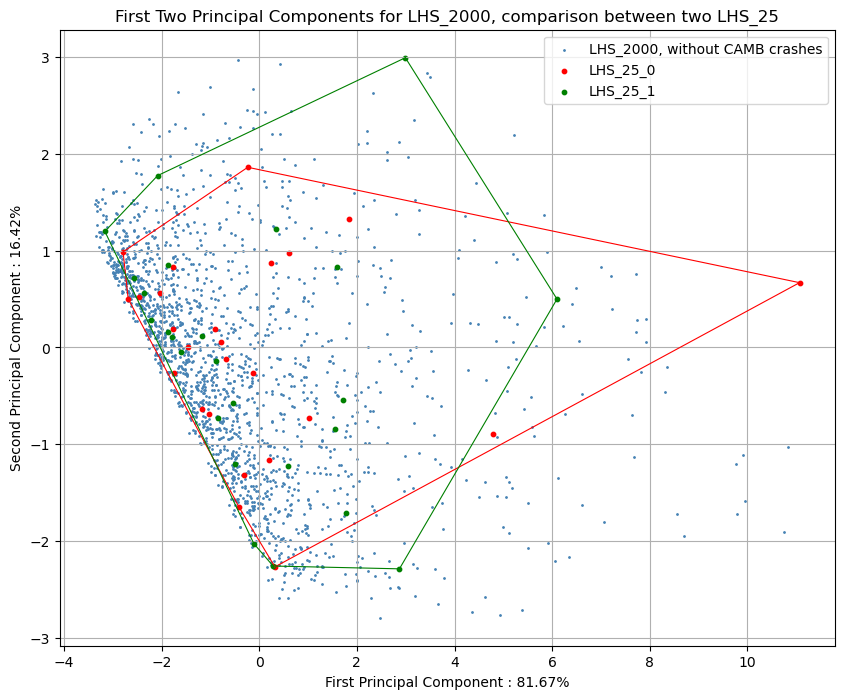

In [6]:
#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)
pc25_test = project_new_data(l25_test_files, scaler, pca)
pc25_train = project_new_data(l25_train_files, scaler, pca)
pc25_opt = project_new_data(l25_train_files, scaler, pca)
pc25_kmeans = project_new_data(l25_kmeans, scaler, pca)
pc50_0 = project_new_data(l50_0, scaler, pca)
pc50_1 = project_new_data(l50_1, scaler, pca)
pc2000_restricted = project_new_data(l2000_restricted, scaler, pca)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]
    
#######################################################################
# PLOTS 
######################################################################

#PLOTS buttons
convexhull = 1
camb_crashes = 0

plt.figure(figsize=(10, 8))
#plt.scatter(pc2000[:, 0], pc2000[:, 1],s=1,alpha=1,color='orangered',label='LHS_2000')
plt.scatter(pc2000_camb[:, 0], pc2000_camb[:, 1],s=1,alpha=1,color='steelblue',label='LHS_2000, without CAMB crashes')
#plt.scatter(pc2000_restricted[:, 0], pc2000_restricted[:, 1],s=1,alpha=1,color='firebrick',label='LHS_2000 restricted intervals')
#plt.scatter(pc25_opt[:, 0], pc25_opt[:, 1],s=10,alpha=1,color='red',label='100 opt')
#plt.scatter(pc25_test[:, 0], pc25_test[:, 1],s=10,alpha=1,color='red',label='LHS_25_test (restricted intervals)')
#plt.scatter(pc25_train[:, 0], pc25_train[:, 1],s=10,alpha=1,color='red',label='LHS_25_train (LHS_27 - 2 CAMB crash)')
plt.scatter(pc50_0[:, 0], pc50_0[:, 1],s=10,alpha=1,color='red',label='LHS_25_0')
plt.scatter(pc50_1[:, 0], pc50_1[:, 1],s=10,alpha=1,color='green',label='LHS_25_1')
if convexhull :
    #convex_plot(pc2000_restricted, 'firebrick')
    convex_plot(pc50_0, 'red')
    convex_plot(pc50_1, 'green')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_2000, comparison between two LHS_25')
plt.legend()
plt.grid()
plt.show()

In [8]:
len(pc2000_camb)

1880

In [ ]:
opt_indices_rest_2D = maximin_distance_2D(pc2000_camb, 100, pc2000)
opt_pc25_rest = pc2000[opt_indices_rest_2D]

convexhull=0
fig= plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:,0],pc2000_camb[:,1], s=2, alpha=1,color='skyblue', label='LHS_2000 without CAMB crashes')
plt.scatter(pc2000[opt_indices_rest_2D,0],pc2000[opt_indices_rest_2D,1], color='green', s=5, label='Optimized 25CPs maximizing distance') 
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
if convexhull:
    convex_plot(opt_pc25_rest, 'green')
plt.legend()
plt.title('First Two Principal For LHS_25_0 + optimized 25CPs, without CAMB crashes')
plt.tight_layout()
plt.grid()
plt.show()

In [ ]:
plot_projections(pc2000_camb,opt_pc25_rest,title = 'First Two PC',label='Selected points')

In [ ]:
# EXPORT NEW COSMOLOGIES DATASET
params_list = ['Om','S8','h','w0','sig8','Oc','zmax','lmax','final_As','final_sig8']
param_path_2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"
params_2000 = pd.read_csv(param_path_2000)
params_2000 = params_2000[params_list]
opt_25_lhs_1D = params_2000.iloc[opt_indices_rest_2D, :]

#params_25_0 = pd.read_csv(param_path_l25_0)
#params_25_0 = params_25_0[params_25_0['camb_res']!=0]
#params_25_0 = params_25_0[params_list]

#opt_50_lhs_1D = pd.concat([opt_25_lhs_1D,params_25_0])
opt_25_lhs_1D = opt_25_lhs_1D.reset_index(drop=True)

opt_25_lhs_1D.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/lhs_100_opt_train.csv')

In [ ]:
indices_opt_25 = opt_kmeans(pc2000_restricted,25)
opt_val_25 = pc2000_restricted[indices_opt_25]
opt_indices_rest_2D
convexhull = 1
plt.figure(figsize=(10, 8))
plt.scatter(pc2000_restricted[:, 0], pc2000_restricted[:, 1], s=1, c='skyblue', label='LHS2000 restricted')
plt.scatter(pc2000_restricted[indices_opt_25, 0], pc2000_restricted[indices_opt_25, 1], s=10, c='red', label='Selected points with K-means')
plt.scatter(pc2000_restricted[opt_indices_rest_2D, 0], pc2000_restricted[opt_indices_rest_2D, 1], s=10, c='green', label='Selected points with iterative maximizing distance')
plt.title('First two PC and selected points with two methods')
if convexhull :
    convex_plot(pc2000_restricted[indices_opt_25], 'red')
    convex_plot(pc2000_restricted[opt_indices_rest_2D], 'green')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.legend()
plt.show()

In [ ]:
plot_projections(pc2000_camb,opt_val_25,title = 'First Two PC',label='Selected points with iterative maximizing distance')

TEST PCA IMAGES

In [ ]:
test25_files = import_images('/net/GECO/pisco/SHEAR2COSMO/DBB_TEST_25/cartesian')

# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=6)

# PCA
principal_components = pca.fit_transform(test25_files)

explained_variance = pca.explained_variance_ratio_

#Explained variance
fc1 = explained_variance[0]
fc2 = explained_variance[1]
    
#######################################################################
# PLOTS 
######################################################################

# Plot explained variance ratio
plt.figure(figsize=(10, 7))
plt.bar(range(0, pc25.n_components_), pc25.explained_variance_ratio_, alpha=0.5, align='center')
plt.plot(np.cumsum(explained_variance), marker='o')
plt.ylabel('Variance proportion')
plt.xlabel('Principal components')
plt.title('Variance explained by each component')
plt.grid()
plt.show()



In [ ]:
np.shape(test25_files)

In [ ]:
plt.figure(figsize=(10, 8))
plt.scatter(pc50_1[:, 0], pc50_1[:, 1],s=10,alpha=1,color='green',label='LHS_25_1')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_2000, comparison between two LHS_25')
plt.legend()
plt.grid()
plt.show()

TEST SAMPLING 2.

In [ ]:
# IMPORT FILES
l2000_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'

l2000_files = import_2pcf(l2000_path)

print("Shape l2000 : ",np.shape(l2000_files))

# PARAMETERS WITH CAMB CRASHES
param_path_l2000 = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

In [ ]:
#####################################################################
# Create PCA and SCALER
scaler = StandardScaler()
pca = PCA(n_components=2)

######################################################################
# APPLY PCA ON BIG DATASET AND PROJECT NEW DATA
pc2000, explained_variance2000 = pca_fn(l2000_files, scaler, pca)
pc2000_camb = pca_without_camb_crash(param_path_l2000,pc2000)

#Explained variance
fc1 = explained_variance2000[0]
fc2 = explained_variance2000[1]
    
#######################################################################
# PLOTS 
######################################################################

#PLOTS buttons
convexhull = 0
camb_crashes = 0

plt.figure(figsize=(10, 8))
plt.scatter(pc2000_camb[:, 0], pc2000_camb[:, 1],s=1,alpha=0.6,color='dodgerblue',label='LHS_2000')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components for LHS_25_0, without CAMB crashes')
plt.legend()
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.grid()
plt.show()

In [ ]:
from matplotlib.transforms import Affine2D
from pyDOE import lhs

params = pd.read_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv')
Om = params['Om']
S8 = params['S8']

def rotate_points(x, y, angle_degrees):
    angle_rad = np.deg2rad(angle_degrees)
    rotation_matrix = np.array([[np.cos(angle_rad), -np.sin(angle_rad)],
                                [np.sin(angle_rad), np.cos(angle_rad)]])
    rotated_points = np.dot(rotation_matrix, np.vstack([x, y]))
    return np.column_stack((rotated_points))


rotated = rotate_points(pc2000_camb[:, 0], pc2000_camb[:, 1], -45)
scaler = MinMaxScaler()
data_normalized = scaler.fit_transform(rotated)

pt = PowerTransformer(method='yeo-johnson')

data_trans = pt.fit_transform(data_normalized)

num_lines = 25
x_values = np.linspace(0, 1, num_lines)**2
x_values = x_values / x_values.max()  # Normalize


fig, ax = plt.subplots(figsize=(10,8))
scatter = ax.scatter(data_normalized[:,0], data_normalized[:,1], s=1,c=Om[params["camb_res"]==1],cmap='magma')
# vertical lines
for x in x_values:
    ax.plot(np.ones(100)*x, np.linspace(0,1,100), color='blue', linestyle='--', alpha=0.7,linewidth=1)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.plot(np.linspace(0,1),-np.linspace(0,1)+0.6)
plt.xlabel('First Principal Component (Transformed)')
plt.ylabel('Second Principal Component (Transformed)')
plt.title('First Two Principal Components with Power Transformation')
cbar = plt.colorbar(scatter)
cbar.set_label("ouais")
plt.legend()
plt.show()

[0.00467654 0.63830021]
[0.01584465 0.84079871]
[0.02294695 0.96222802]
[0.02474423 0.65811935]
[0.02904552 0.92949255]
[0.03510782 0.61002807]
[0.04015715 0.80357059]
[0.04945876 0.82111129]
[0.05455143 0.61463141]
[0.06285755 0.68657808]
[0.06677217 0.63787965]
[0.07190394 0.685063  ]
[0.08049784 0.56104692]
[0.09589428 0.86778084]
[0.11203237 0.72845188]
[0.12395254 0.89154554]
[0.13683831 0.77331347]
[0.15016441 0.84815664]
[0.18660542 0.76791864]
[0.22252766 0.74716855]
[0.23917286 0.78421952]
[0.29270054 0.6104729 ]
[0.38290065 0.57350961]
[0.41782243 0.64881677]
[0.75969239 0.44176129]


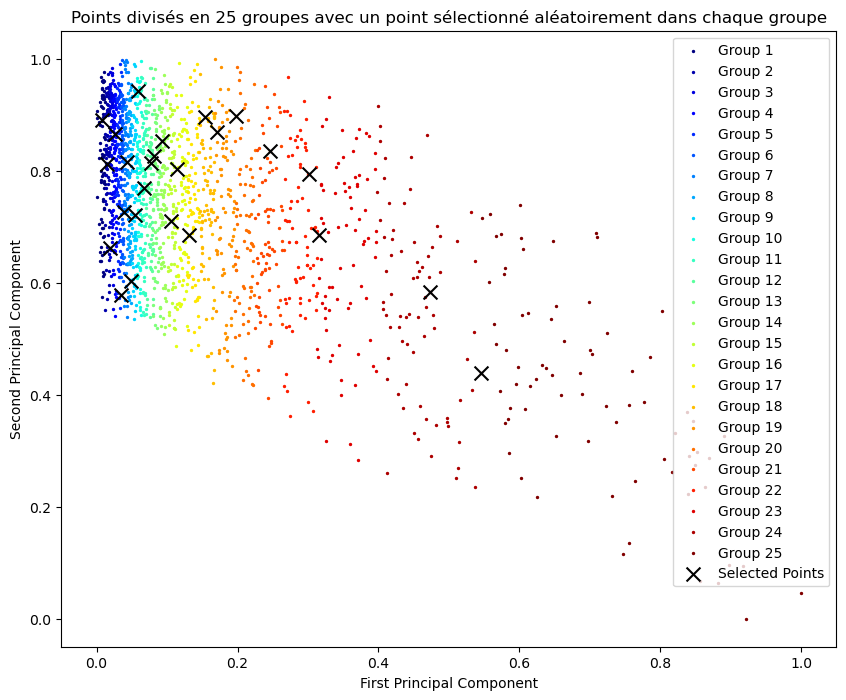

In [281]:
import numpy as np
import matplotlib.pyplot as plt

# Simulons des données pour l'exemple
data = data_normalized

# Trier les points selon la première composante principale
sorted_indices = np.argsort(data[:, 0])
sorted_data = data[sorted_indices]

# Diviser les points triés en 25 groupes de taille égale
n_groups = 25
groups = np.array_split(sorted_data, n_groups)

# Sélectionner aléatoirement un point dans chaque groupe
for i, group in enumerate(groups):
    candidate_point = group[np.random.choice(group.shape[0])]
    print(candidate_point)
selected_points = np.array([group[np.random.choice(group.shape[0])] for group in groups])


# Optionnel: Afficher les groupes et les points sélectionnés pour visualiser la division
plt.figure(figsize=(10, 8))
colors = plt.cm.jet(np.linspace(0, 1, n_groups))
for i, group in enumerate(groups):
    plt.scatter(group[:, 0], group[:, 1], color=colors[i], label=f'Group {i+1}',s=2)
plt.scatter(selected_points[:, 0], selected_points[:, 1], color='black', marker='x', s=100, label='Selected Points')
plt.title("Points divisés en 25 groupes avec un point sélectionné aléatoirement dans chaque groupe")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend()
plt.show()

# 'selected_points' contient les points sélectionnés aléatoirement


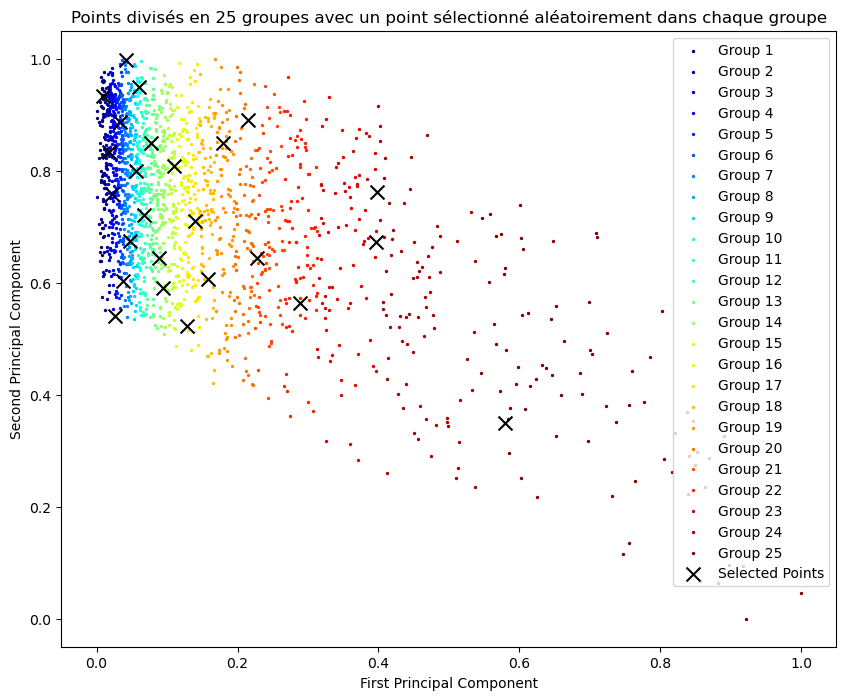

In [309]:
selected_points = []

for i, group in enumerate(groups):
    min_dist = 1e-6 
    if len(selected_points)==0:
        np.random.seed(0)
        candidate_point = group[np.random.choice(group.shape[0])]
        selected_points.append(list(candidate_point))
    else :
        threshold = 0.05
        while min_dist<threshold:
            candidate_point = group[np.random.choice(group.shape[0])]
            distances = np.linalg.norm(np.array(selected_points) - np.array([candidate_point]*len(selected_points)), axis=1)
            min_dist = np.min(distances)
        selected_points.append(list(candidate_point))
        
selected_points=np.array(selected_points)
selected_indices = find_closest_points(selected_points,data_normalized)

plt.figure(figsize=(10, 8))
colors = plt.cm.jet(np.linspace(0, 1, n_groups))
for i, group in enumerate(groups):
    plt.scatter(group[:, 0], group[:, 1], color=colors[i], label=f'Group {i+1}',s=2)
plt.scatter(selected_points[:, 0], selected_points[:, 1], color='black', marker='x', s=100, label='Selected Points')
plt.title("Points divisés en 25 groupes avec un point sélectionné aléatoirement dans chaque groupe")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend()
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


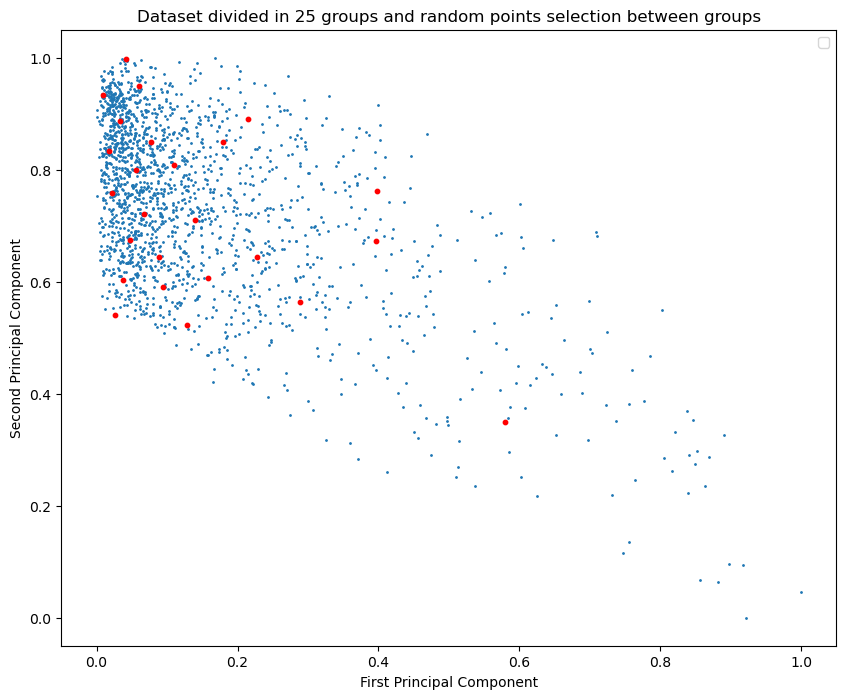

/tmp/ipykernel_1397721/3599107995.py:231: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


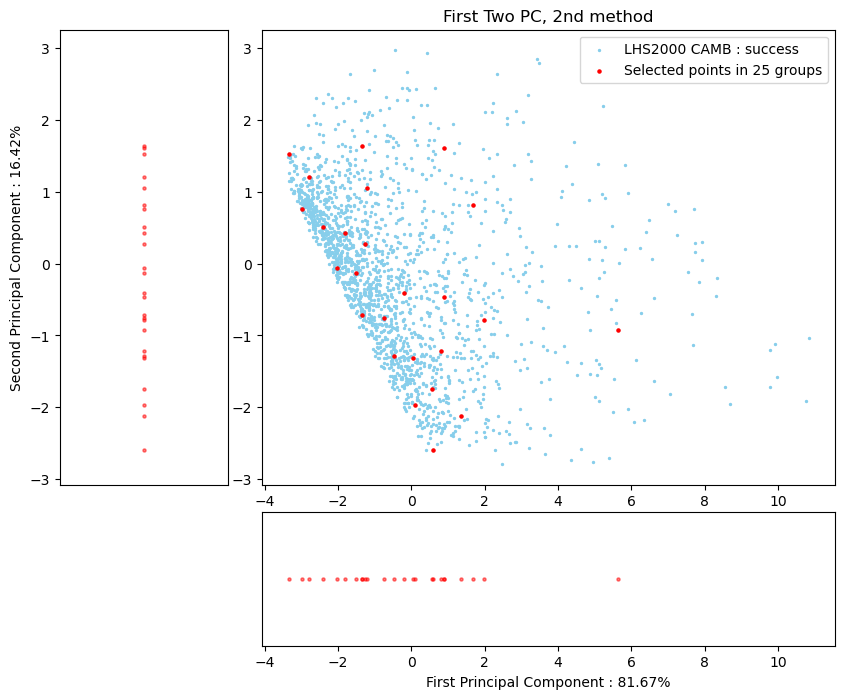

In [319]:
plt.figure(figsize=(10, 8))
plt.scatter(data_normalized[:,0],data_normalized[:,1],s=1)
plt.scatter(data_normalized[selected_indices,0],data_normalized[selected_indices,1],s=10,color='red')
plt.title("Dataset divided in 25 groups and random points selection between groups")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend()
plt.show()

final_25groups_indices = find_closest_points(pc2000_camb[selected_indices],pc2000)
final_25groups_points = params_2000.iloc[final_25groups_indices,:]
final_25groups_points = final_25groups_points.reset_index(drop=True)

final_25groups_points.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/sampling/opt_lhs/25_groups.csv')

plot_projections(pc2000_camb,pc2000_camb[selected_indices],title = 'First Two PC, 2nd method',label='Selected points in 25 groups')